In [9]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DAY7_DIR = Path(r"C:\Users\Comp\Linkific-Tasks-Upload\Day 7")
DATA_FILE = DAY7_DIR / "data" / "ecommerce_sales.csv"
OUTPUT_DIR = DAY7_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_FILE)
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["sales"] = df["quantity"] * df["unit_price"]

df = df.dropna(subset=["order_date", "sales"])
df = df.drop_duplicates(subset=["order_id"], keep="first")
df = df.sort_values("order_date")

print("Date range:", df["order_date"].min(), "to", df["order_date"].max())
print("Number of orders:", df["order_id"].nunique())
display(df.head())


Date range: 2026-01-05 00:00:00 to 2026-03-20 00:00:00
Number of orders: 12


,order_id,customer,category,quantity,unit_price,order_date,rating,sales
0,1001,Asha,Electronics,2,1200,2026-01-05,5.0,2400
1,1002,Rahul,Clothing,3,500,2026-01-08,4.0,1500
2,1003,Meera,Electronics,1,2500,2026-01-12,5.0,2500
3,1004,Arjun,Home,2,800,2026-01-15,3.0,1600
4,1005,Asha,Clothing,4,450,2026-02-02,4.0,1800


In [10]:

daily_sales = (
    df.set_index("order_date")["sales"]
    .resample("D")
    .sum()
)

monthly_sales = daily_sales.resample("MS").sum()

print("Monthly sales totals:")
display(monthly_sales)

monthly_sales.to_csv(
    OUTPUT_DIR / "notebook_monthly_eda.csv",
    header=["total_sales"]
)


Monthly sales totals:


order_date
2026-01-01    8000
2026-02-01    7800
2026-03-01    5700
Freq: MS, Name: sales, dtype: int64

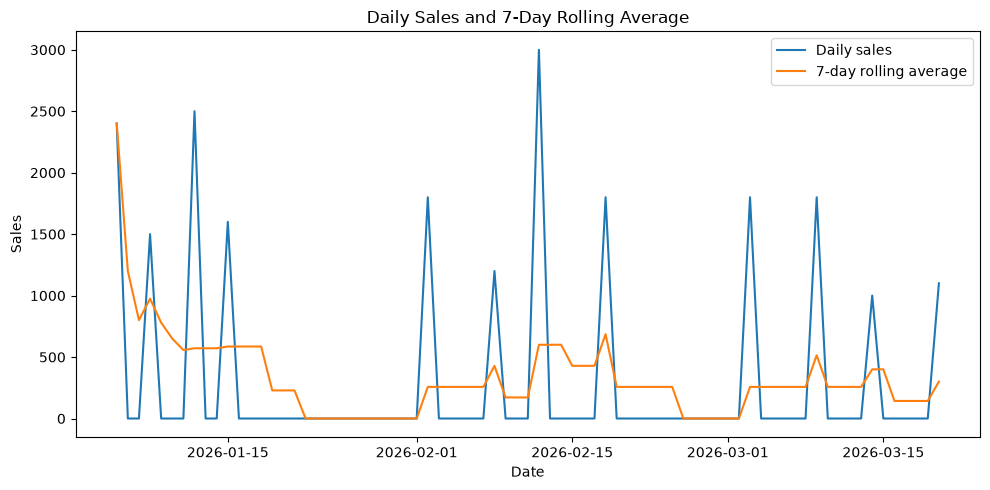

In [11]:

rolling_average = daily_sales.rolling(
    window=7,
    min_periods=1
).mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_sales.index, daily_sales.values, label="Daily sales")
plt.plot(
    rolling_average.index,
    rolling_average.values,
    label="7-day rolling average"
)
plt.title("Daily Sales and 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()


In [12]:

findings = [
    f"Start date: {daily_sales.index.min().date()}",
    f"End date: {daily_sales.index.max().date()}",
    f"Total sales: {daily_sales.sum():.2f}",
    f"Average daily sales: {daily_sales.mean():.2f}",
    f"Highest daily sales: {daily_sales.max():.2f}",
    f"Lowest daily sales: {daily_sales.min():.2f}",
    f"Number of days: {len(daily_sales)}"
]

findings_path = DAY7_DIR / "reports" / "time_series_eda_findings.txt"
findings_path.parent.mkdir(parents=True, exist_ok=True)
findings_path.write_text("\n".join(findings), encoding="utf-8")

print("\n".join(findings))
print("\nSaved to:", findings_path)


Start date: 2026-01-05
End date: 2026-03-20
Total sales: 21500.00
Average daily sales: 286.67
Highest daily sales: 3000.00
Lowest daily sales: 0.00
Number of days: 75

Saved to: C:\Users\Comp\Linkific-Tasks-Upload\Day 7\reports\time_series_eda_findings.txt


In [13]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DAY7_DIR = Path(r"C:\Users\Comp\Linkific-Tasks-Upload\Day 7")
DATA_FILE = DAY7_DIR / "data" / "ecommerce_sales.csv"
OUTPUT_DIR = DAY7_DIR / "outputs"
REPORT_DIR = DAY7_DIR / "reports"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_FILE)
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["sales"] = df["quantity"] * df["unit_price"]

# Remove invalid dates and repeated order IDs for analysis
df = df.dropna(subset=["order_date", "sales"])
df = df.drop_duplicates(subset=["order_id"], keep="first")
df = df.sort_values("order_date")

print("Date range:", df["order_date"].min(), "to", df["order_date"].max())
print("Unique orders:", df["order_id"].nunique())
display(df.head())


Date range: 2026-01-05 00:00:00 to 2026-03-20 00:00:00
Unique orders: 12


,order_id,customer,category,quantity,unit_price,order_date,rating,sales
0,1001,Asha,Electronics,2,1200,2026-01-05,5.0,2400
1,1002,Rahul,Clothing,3,500,2026-01-08,4.0,1500
2,1003,Meera,Electronics,1,2500,2026-01-12,5.0,2500
3,1004,Arjun,Home,2,800,2026-01-15,3.0,1600
4,1005,Asha,Clothing,4,450,2026-02-02,4.0,1800


In [14]:

daily_sales = (
    df.set_index("order_date")["sales"]
    .resample("D")
    .sum()
)

monthly_sales = daily_sales.resample("MS").sum()

print("Monthly sales totals:")
display(monthly_sales)

monthly_sales.to_csv(
    OUTPUT_DIR / "notebook_monthly_eda.csv",
    header=["total_sales"]
)


Monthly sales totals:


order_date
2026-01-01    8000
2026-02-01    7800
2026-03-01    5700
Freq: MS, Name: sales, dtype: int64

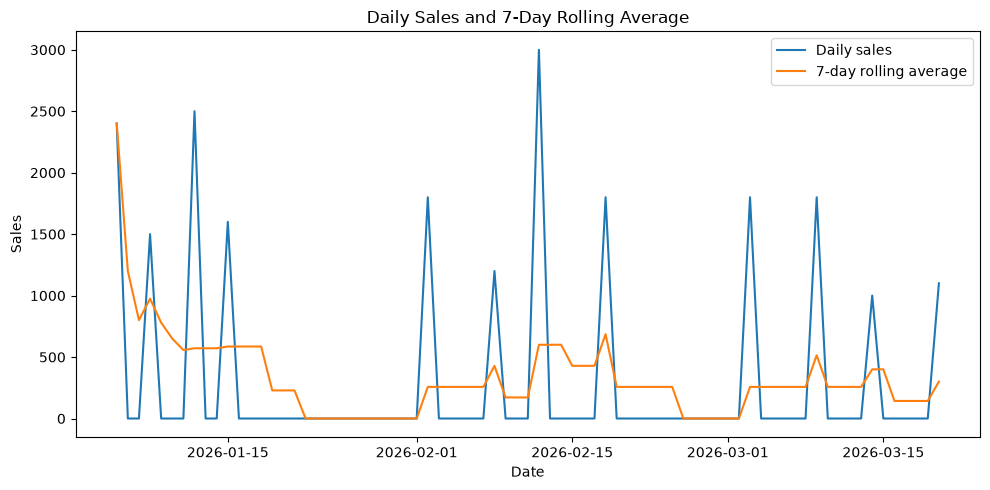

In [15]:

rolling_average = daily_sales.rolling(
    window=7, min_periods=1
).mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_sales.index, daily_sales.values, label="Daily sales")
plt.plot(
    rolling_average.index,
    rolling_average.values,
    label="7-day rolling average"
)
plt.title("Daily Sales and 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()


In [16]:

findings = [
    f"Start date: {daily_sales.index.min().date()}",
    f"End date: {daily_sales.index.max().date()}",
    f"Total sales: {daily_sales.sum():.2f}",
    f"Average daily sales: {daily_sales.mean():.2f}",
    f"Highest daily sales: {daily_sales.max():.2f}",
    f"Lowest daily sales: {daily_sales.min():.2f}",
    f"Number of days: {len(daily_sales)}"
]

findings_path = REPORT_DIR / "time_series_eda_findings.txt"
findings_path.write_text("\n".join(findings), encoding="utf-8")

print("\n".join(findings))
print("\nSaved to:", findings_path)


Start date: 2026-01-05
End date: 2026-03-20
Total sales: 21500.00
Average daily sales: 286.67
Highest daily sales: 3000.00
Lowest daily sales: 0.00
Number of days: 75

Saved to: C:\Users\Comp\Linkific-Tasks-Upload\Day 7\reports\time_series_eda_findings.txt
